# HR Attrition Analysis

Which employees leave, and what do they have in common? Descriptive analysis of 1,470 employee records.

**Data:** `data/hr_attrition_clean.csv`, produced by `scripts/prepare_data.py` from the raw HR workbook (IBM HR Analytics sample data; fictional employees).
**Scope:** descriptive only. Rates below show *association*, not cause.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, GREY = "#2b6cb0", "#dd6b20", "#a0aec0"
IMG = Path("../images"); IMG.mkdir(exist_ok=True)

df = pd.read_csv("../data/hr_attrition_clean.csv")
df["left"] = (df["attrition"] == "Yes").astype(int)
df.shape

(1470, 33)

## 1. Data quality

In [2]:
print("missing values :", int(df.isna().sum().sum()))
print("duplicate rows :", int(df.duplicated().sum()))
print("unique employee_id:", df["employee_id"].is_unique)
df[["age", "monthly_income", "years_at_company", "distance_from_home"]].describe().round(1)

missing values : 0
duplicate rows : 0
unique employee_id: True


,age,monthly_income,years_at_company,distance_from_home
count,1470.0,1470.0,1470.0,1470.0
mean,36.9,6502.9,7.0,9.2
std,9.1,4708.0,6.1,8.1
min,18.0,1009.0,0.0,1.0
25%,30.0,2911.0,3.0,2.0
50%,36.0,4919.0,5.0,7.0
75%,43.0,8379.0,9.0,14.0
max,60.0,19999.0,40.0,29.0


## 2. Headline KPIs

In [3]:
kpi = {
    "Employees": len(df),
    "Attrition count": int(df["left"].sum()),
    "Attrition rate %": round(df["left"].mean() * 100, 2),
    "Active employees": int((df["left"] == 0).sum()),
    "Average age": round(df["age"].mean(), 2),
}
pd.Series(kpi)

Employees           1470.00
Attrition count      237.00
Attrition rate %      16.12
Active employees    1233.00
Average age           36.92
dtype: float64

## 3. Helper: attrition rate by any column
`rate_table` returns headcount, leavers and attrition rate for each group, and `bar_rate` plots the rate against the company average (16.1%).

In [4]:
avg = df["left"].mean() * 100

def rate_table(col, order=None):
    t = df.groupby(col, observed=True)["left"].agg(employees="count", left="sum", rate=lambda s: s.mean() * 100)
    t["rate"] = t["rate"].round(1)
    return t.loc[order] if order is not None else t.sort_values("rate", ascending=False)

def bar_rate(t, title, fname, horizontal=False, figsize=(7, 3.6)):
    fig, ax = plt.subplots(figsize=figsize)
    colors = [ORANGE if r > avg else BLUE for r in t["rate"]]
    labels = [str(i) for i in t.index]
    if horizontal:
        ax.barh(labels[::-1], t["rate"][::-1], color=colors[::-1]); ax.axvline(avg, color=GREY, ls="--")
        ax.set_xlabel("Attrition rate (%)")
        for y, (r, n) in enumerate(zip(t["rate"][::-1], t["employees"][::-1])): ax.text(r + .5, y, f"{r}%  (n={n})", va="center", fontsize=8)
        ax.set_xlim(0, t["rate"].max() * 1.3)
    else:
        ax.bar(labels, t["rate"], color=colors); ax.axhline(avg, color=GREY, ls="--")
        ax.set_ylabel("Attrition rate (%)")
        for x, (r, n) in enumerate(zip(t["rate"], t["employees"])): ax.text(x, r + .6, f"{r}%", ha="center", fontsize=8)
        ax.set_ylim(0, t["rate"].max() * 1.2)
    ax.set_title(title + f"   (dashed = company average {avg:.1f}%)", fontsize=10, loc="left")
    fig.tight_layout(); fig.savefig(IMG / fname, bbox_inches="tight"); plt.show()

## 4. Department: count vs rate
R&D loses the most people (count) but has the lowest *rate*. Headcount alone is misleading.

,employees,left,rate
department,,,
Sales,446,92,20.6
HR,63,12,19.0
R&D,961,133,13.8


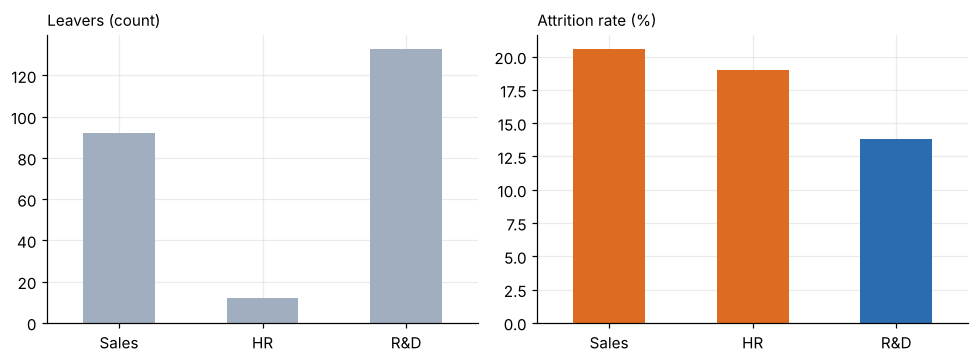

In [5]:
t = rate_table("department"); display(t)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
t["left"].plot.bar(ax=ax[0], color=GREY, rot=0); ax[0].set_title("Leavers (count)", loc="left", fontsize=10)
t["rate"].plot.bar(ax=ax[1], color=[ORANGE if r > avg else BLUE for r in t["rate"]], rot=0); ax[1].set_title("Attrition rate (%)", loc="left", fontsize=10)
for a in ax: a.set_xlabel("")
fig.tight_layout(); fig.savefig(IMG / "01_department.png", bbox_inches="tight"); plt.show()

## 5. Age band

,employees,left,rate
age_band,,,
Under 25,97,38,39.2
25-34,554,112,20.2
35-44,505,51,10.1
45-54,245,25,10.2
55+,69,11,15.9


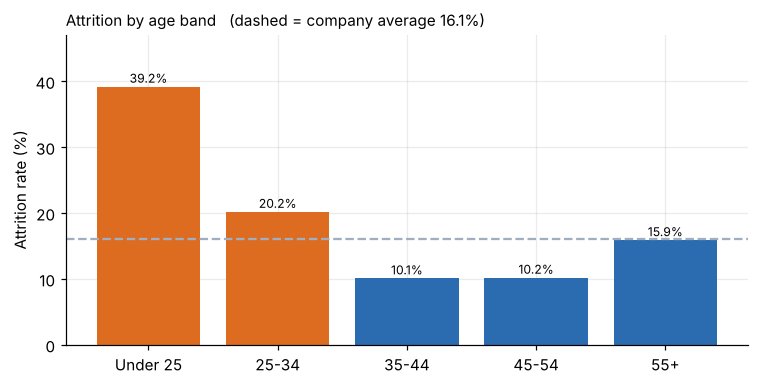

In [6]:
df["age_band"] = pd.cut(df["age"], [0, 24, 34, 44, 54, 100], labels=["Under 25", "25-34", "35-44", "45-54", "55+"])
t = rate_table("age_band", order=["Under 25", "25-34", "35-44", "45-54", "55+"]); display(t)
bar_rate(t, "Attrition by age band", "02_age_band.png")

## 6. Overtime

,employees,left,rate
over_time,,,
Yes,416,127,30.5
No,1054,110,10.4


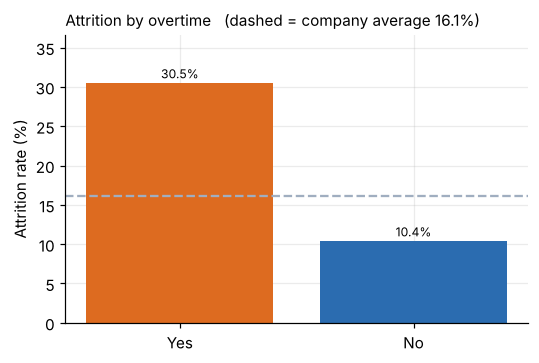

In [7]:
t = rate_table("over_time"); display(t)
bar_rate(t, "Attrition by overtime", "03_overtime.png", figsize=(5, 3.4))

## 7. Job role

,employees,left,rate
job_role,,,
Sales Representative,83,33,39.8
Laboratory Technician,259,62,23.9
Human Resources,52,12,23.1
Sales Executive,326,57,17.5
Research Scientist,292,47,16.1
Healthcare Representative,131,9,6.9
Manufacturing Director,145,10,6.9
Manager,102,5,4.9
Research Director,80,2,2.5


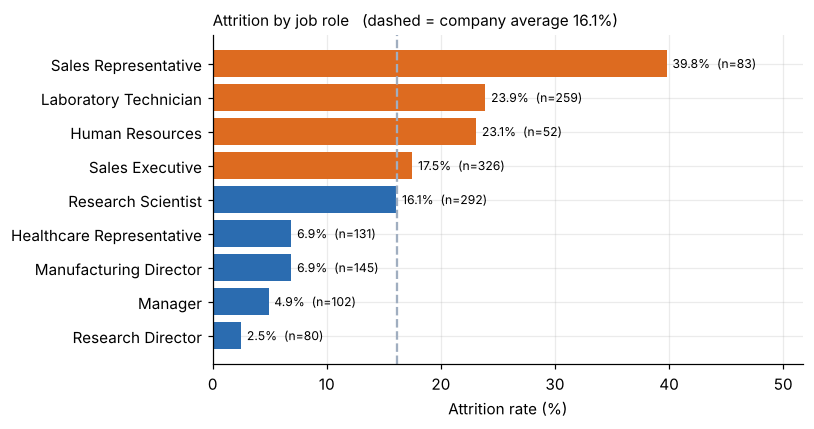

In [8]:
t = rate_table("job_role"); display(t)
bar_rate(t, "Attrition by job role", "04_job_role.png", horizontal=True, figsize=(7.5, 4))

## 8. Tenure

,employees,left,rate
tenure_band,,,
0-1 yr,215,75,34.9
2-3 yrs,255,47,18.4
4-5 yrs,306,40,13.1
6-10 yrs,448,55,12.3
10+ yrs,246,20,8.1


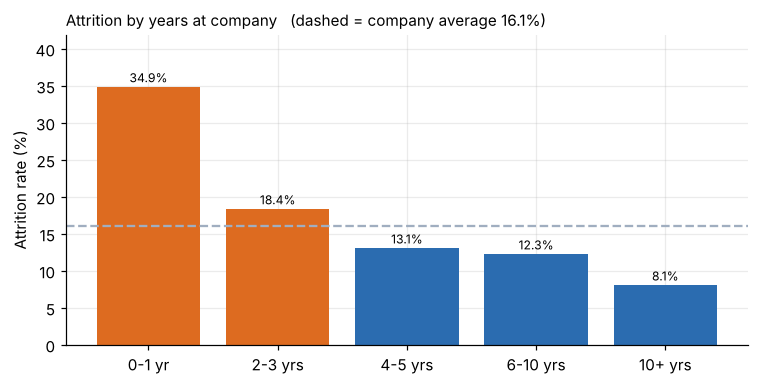

In [9]:
df["tenure_band"] = pd.cut(df["years_at_company"], [-1, 1, 3, 5, 10, 100], labels=["0-1 yr", "2-3 yrs", "4-5 yrs", "6-10 yrs", "10+ yrs"])
t = rate_table("tenure_band", order=["0-1 yr", "2-3 yrs", "4-5 yrs", "6-10 yrs", "10+ yrs"]); display(t)
bar_rate(t, "Attrition by years at company", "05_tenure.png")

## 9. Monthly income quartile

,employees,left,rate
income_quartile,,,
Q1 (lowest),369,108,29.3
Q2,366,52,14.2
Q3,367,39,10.6
Q4 (highest),368,38,10.3


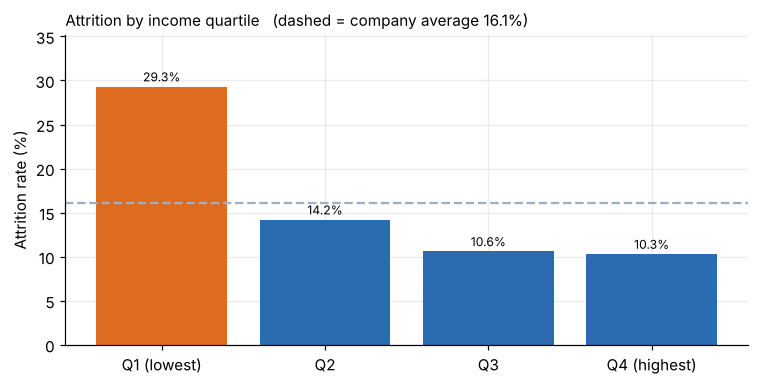

In [10]:
df["income_quartile"] = pd.qcut(df["monthly_income"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
t = rate_table("income_quartile", order=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]); display(t)
bar_rate(t, "Attrition by income quartile", "06_income.png")

## 10. Overtime x marital status

over_time,No,Yes
marital_status,,
Divorced,6.1,19.2
Married,8.4,23.1
Single,16.2,49.6


over_time,No,Yes
marital_status,,
Divorced,228,99
Married,487,186
Single,339,131


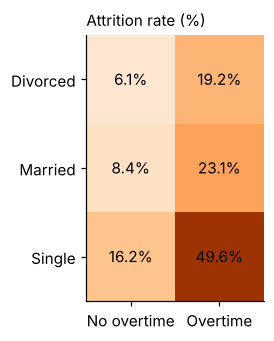

In [11]:
pv = df.pivot_table(index="marital_status", columns="over_time", values="left", aggfunc="mean").mul(100).round(1)
cnt = df.pivot_table(index="marital_status", columns="over_time", values="left", aggfunc="count")
display(pv, cnt)
fig, ax = plt.subplots(figsize=(4.6, 3.2))
im = ax.imshow(pv.values, cmap="Oranges", vmin=0, vmax=55)
ax.set_xticks(range(2), ["No overtime", "Overtime"]); ax.set_yticks(range(3), pv.index); ax.grid(False)
for i in range(3):
    for j in range(2): ax.text(j, i, f"{pv.values[i, j]}%", ha="center", va="center", fontsize=10)
ax.set_title("Attrition rate (%)", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(IMG / "07_overtime_marital.png", bbox_inches="tight"); plt.show()

## 11. A high-risk profile

In [12]:
seg = df[(df["age"] < 35) & (df["marital_status"] == "Single") & (df["over_time"] == "Yes")]
print(f"Under 35 + single + overtime: {len(seg)} employees, {seg['left'].sum()} left = {seg['left'].mean()*100:.1f}% (company average {avg:.1f}%)")

Under 35 + single + overtime: 68 employees, 45 left = 66.2% (company average 16.1%)


## 12. Findings
Numbers are computed above and match the SQL queries in `sql/analysis_queries.sql`.

1. **Overtime is the strongest single signal:** 30.5% attrition with overtime vs 10.4% without. Single employees working overtime leave at 49.6%.
2. **Early-career and early-tenure employees leave most:** under-25s 39.2%, first-year employees 34.9%.
3. **Role matters more than department:** Sales Representatives 39.8% vs Research Directors 2.5%. R&D has the most leavers (133) but the lowest rate (13.8%).
4. **Pay band:** lowest income quartile 29.3% vs about 10% in the top two.
5. **Small high-risk group:** under 35, single, overtime = 68 people, 66.2% left. Small sample, so treat it as a lead to investigate, not a rule.

**Limits:** descriptive analysis on a sample dataset; no causal claims and no prediction model were built.